# Session 12 — Read a paper, reproduce a claim

Session 7 used LoRA as a tool. This session reads the paper that introduced it, Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models* (arXiv:2106.09685, version 2), as a set of claims with evidence, and tests three of them at small scale with Session 7's robot-log task on Qwen2.5-0.5B-Instruct. Session 11's tools decide which differences are real.

**By the end of the session you should be able to:**

1. map a paper into its question, method, evidence and scale, and say what each table can and cannot support;
2. grade a claim using the paper's own error bars;
3. design a small reproduction, run it, and report honestly which parts held and which did not, and at what scale.

**To run it yourself** you need the packages from Session 7 and Qwen2.5-0.5B-Instruct (about 1 GB, downloaded in Session 6). The notebook trains 24 adapters and took 1,126 s on our laptop GPU, on a machine shared with other work. It is not practical on a CPU. The paper's text and the official `loralib` code are in `_build/papers/`.

The first cell loads the model and copies two of the paper's tables.

In [1]:
import re, json, math, time, copy, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging
logging.set_verbosity_error(); set_seed(0)
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", padding_side="left")
inst = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.bfloat16).to(DEVICE).eval()
for p in inst.parameters(): p.requires_grad = False
# Table 5 and Table 6 of Hu et al. (2021), validation accuracy of GPT-3 175B with LoRA, copied from the paper (arXiv:2106.09685v2)
table5 = pd.DataFrame({"weights adapted": ["Wq", "Wk", "Wv", "Wo", "Wq, Wk", "Wq, Wv", "Wq, Wk, Wv, Wo"], "rank": [8, 8, 8, 8, 4, 4, 2],
                       "WikiSQL (±0.5%)": [70.4, 70.0, 73.0, 73.2, 71.4, 73.7, 73.7], "MultiNLI (±0.1%)": [91.0, 90.8, 91.0, 91.3, 91.3, 91.3, 91.7]})
table6 = pd.DataFrame({"r=1": [68.8, 73.4, 74.1, 90.7, 91.3, 91.2], "r=2": [69.6, 73.3, 73.7, 90.9, 91.4, 91.7], "r=4": [70.5, 73.7, 74.0, 91.1, 91.3, 91.7],
                       "r=8": [70.4, 73.8, 74.0, 90.7, 91.6, 91.5], "r=64": [70.0, 73.5, 73.9, 90.7, 91.4, 91.4]},
                      index=pd.MultiIndex.from_product([["WikiSQL (±0.5%)", "MultiNLI (±0.1%)"], ["Wq", "Wq, Wv", "Wq, Wk, Wv, Wo"]]))
display(table5); display(table6)

,weights adapted,rank,WikiSQL (±0.5%),MultiNLI (±0.1%)
0,Wq,8,70.4,91.0
1,Wk,8,70.0,90.8
2,Wv,8,73.0,91.0
3,Wo,8,73.2,91.3
4,"Wq, Wk",4,71.4,91.3
5,"Wq, Wv",4,73.7,91.3
6,"Wq, Wk, Wv, Wo",2,73.7,91.7


r=1   r=2   r=4   r=8  r=64
WikiSQL (±0.5%)  Wq              68.8  69.6  70.5  70.4  70.0
                 Wq, Wv          73.4  73.3  73.7  73.8  73.5
                 Wq, Wk, Wv, Wo  74.1  73.7  74.0  74.0  73.9
MultiNLI (±0.1%) Wq              90.7  90.9  91.1  90.7  90.7
                 Wq, Wv          91.3  91.4  91.3  91.6  91.4
                 Wq, Wk, Wv, Wo  91.2  91.7  91.7  91.5  91.4

## 1. A map of the paper

Before testing anything, sort the paper into four parts.

- **Question:** can a large pre-trained model be adapted to a task by training a small low-rank update instead of all its weights, with no loss in quality?
- **Method (§4.1):** keep each weight matrix $W_0$ frozen and learn $\Delta W = BA$, with $B$ of size $d \times r$ and $A$ of size $r \times k$ for a small rank $r$. $A$ starts random and $B$ at zero, so the model is unchanged before training, and $\Delta W x$ is scaled by $\alpha / r$. Only attention matrices are adapted; the MLP stays frozen (§4.2).
- **Evidence:** benchmark tables against full fine-tuning and other adapters (§5), then a study of which matrices to adapt (Table 5), which rank to use (Table 6), how the learned directions overlap (Figures 3 and 4) and how $\Delta W$ relates to $W$ (Table 7).
- **Scale:** the analysis in §7 uses GPT-3 175B, on two tasks, WikiSQL and MultiNLI.

The paper also states its own noise: the standard deviation across random seeds is about ±0.5% on WikiSQL and ±0.1% on MultiNLI. That gives us a way to grade its claims. The cell below takes Table 6 and, for each row, compares the gap between the best and the worst rank with that noise.

> **Pause:** in Table 6, which rank is best for $W_q, W_v$ on WikiSQL? Is the evidence strong enough to recommend it?

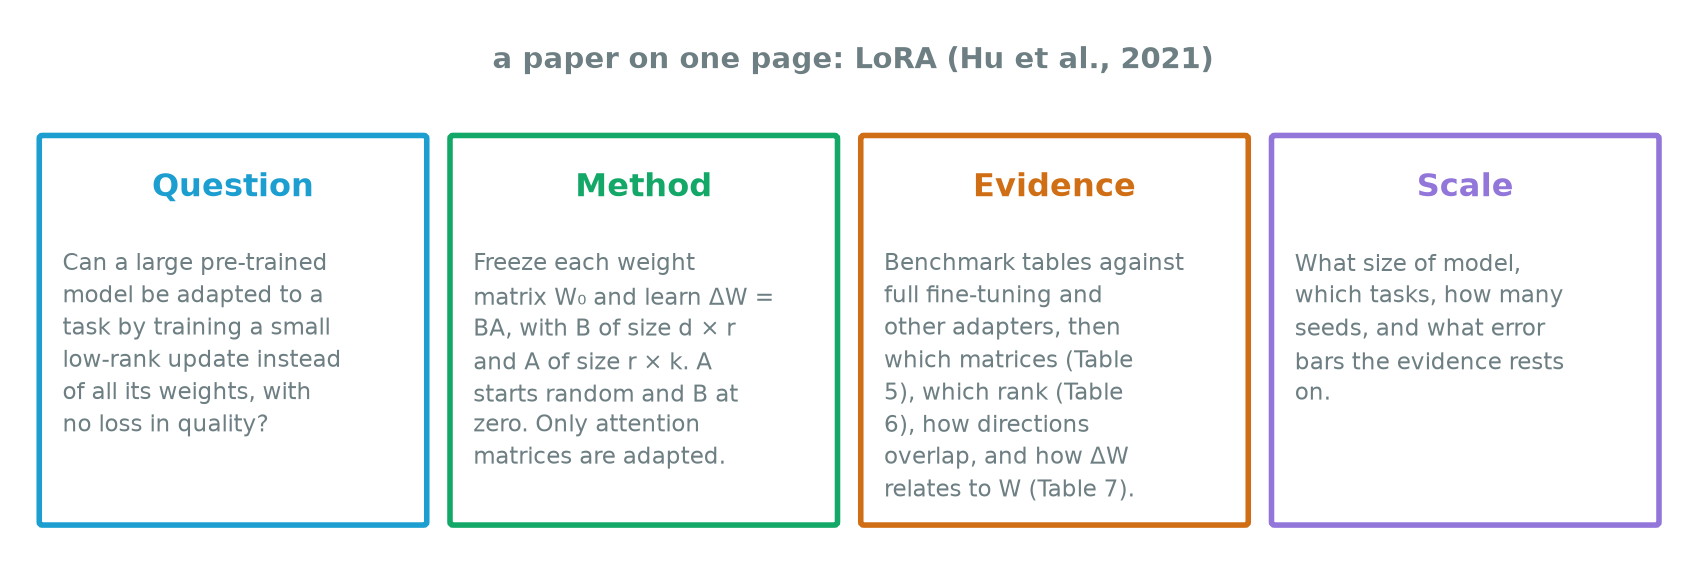

*Figure 12.1 — The paper map: a one-page template with four boxes, question, method, evidence and scale, filled in here for the LoRA paper. The same four boxes can be used for any paper.*

In [2]:
noise = {"WikiSQL (±0.5%)": 0.5, "MultiNLI (±0.1%)": 0.1}
rows = []
for (task, weights), r in table6.iterrows():
    rows.append({"task": task, "weights adapted": weights, "best rank": r.idxmax(), "worst rank": r.idxmin(), "best minus worst": round(r.max() - r.min(), 1),
                 "rank 1 minus best": round(r["r=1"] - r.max(), 1), "seed noise (paper)": noise[task]})
display(pd.DataFrame(rows))

,task,weights adapted,best rank,worst rank,best minus worst,rank 1 minus best,seed noise (paper)
0,WikiSQL (±0.5%),Wq,r=4,r=1,1.7,-1.7,0.5
1,WikiSQL (±0.5%),"Wq, Wv",r=8,r=2,0.5,-0.4,0.5
2,WikiSQL (±0.5%),"Wq, Wk, Wv, Wo",r=1,r=2,0.4,0.0,0.5
3,MultiNLI (±0.1%),Wq,r=4,r=1,0.4,-0.4,0.1
4,MultiNLI (±0.1%),"Wq, Wv",r=8,r=1,0.3,-0.3,0.1
5,MultiNLI (±0.1%),"Wq, Wk, Wv, Wo",r=2,r=1,0.5,-0.5,0.1


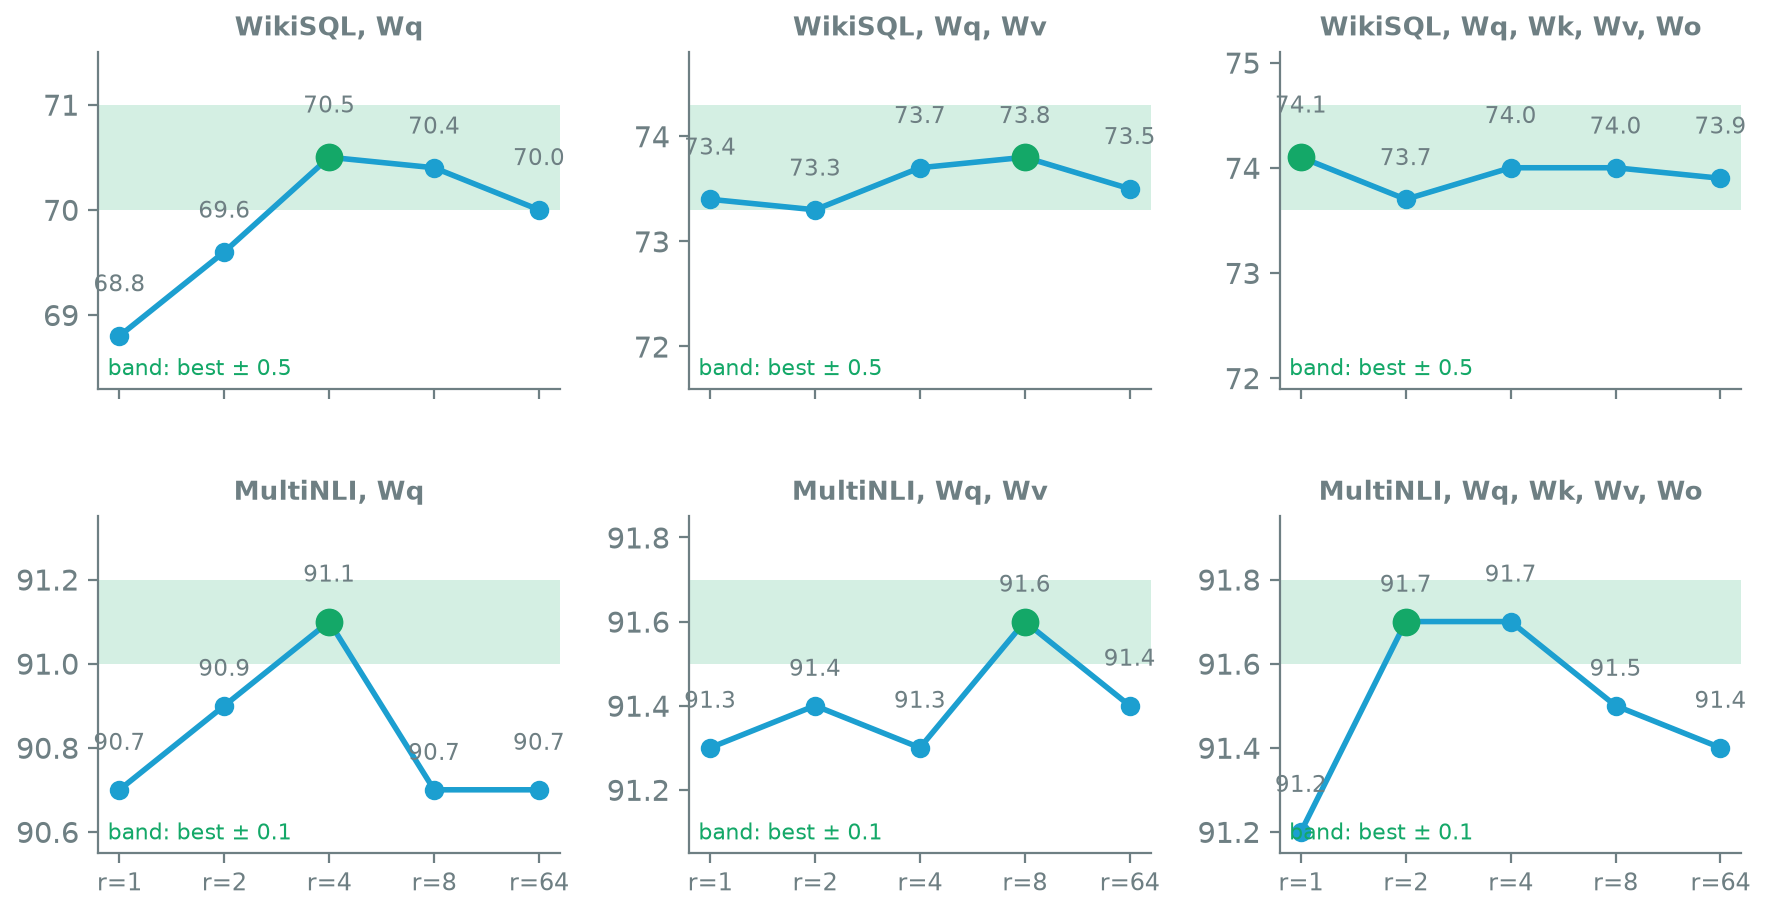

*Figure 12.2 — The paper's Table 6 graded with its own error bars. Each panel shows the accuracy at each rank for one task and one set of adapted matrices; the green band is the best score plus or minus the paper's seed noise (0.5 for WikiSQL, 0.1 for MultiNLI). Where several ranks sit inside the band, the table cannot tell them apart.*

For $W_q, W_v$ on WikiSQL, r = 8 is best with 73.8, and the worst rank is 0.5 points below it, the size of one seed's standard deviation. The table cannot tell these ranks apart, so "r = 8 is best" is not supported. What it does support is the paper's actual claim, that a very small rank is enough: rank 1 is within 0.4 of the best. On MultiNLI, where the noise is smaller, rank 1 is 0.3 below the best for $W_q, W_v$, three times the noise: a small but real cost.

For $W_q$ alone on WikiSQL, the best and worst ranks differ by 1.7, more than three times the noise, and rank 1 is the worst. This supports the paper's second claim, that adapting $W_q$ alone needs a larger rank than adapting $W_q$ and $W_v$ together.

Grading a claim this way takes a minute and needs no GPU. It tells you which sentences of the paper the tables actually back.

## 2. Which matrices to adapt (Table 5)

Table 5 fixes a budget of 18M trainable numbers in GPT-3 and spends it on different attention matrices: rank 8 on one matrix, rank 4 on two, rank 2 on all four. On WikiSQL, $W_v$ or $W_o$ alone (73.0, 73.2) beat $W_q$ or $W_k$ alone (70.4, 70.0), and $W_q, W_v$ together match all four (73.7).

We repeat this with Session 7's task: extract five fields from a robot log line as JSON, training on four layouts and testing on held-out lines from those layouts and from two layouts never seen in training. The next cell copies Session 7's task, LoRA layer and training loop; presenters can skip it on screen.

In [3]:
# The task, the LoRA layer and the training loop are the same as in Session 7.
rng = np.random.default_rng(0)
TEMPLATES = ["{time} robot {robot} battery {battery}% charger {charger} status {status}", "[{time}] {robot}: batt={battery}% chg={charger} state={status}",
             "Robot {robot} reported at {time} that its battery is at {battery} percent, docked at charger {charger}, status: {status}.", "{status} | {robot} | {battery}% | {charger} | {time}",
             "At {time}, unit {robot} (charger {charger}) shows {battery}% charge - {status}.", "{robot}/{charger} @ {time} -> level {battery}, flag {status}"]
SEEN, UNSEEN = [0, 1, 2, 3], [4, 5]
def make_example(t):
    f = {"robot": f"R-{rng.integers(1, 40)}", "battery": int(rng.integers(1, 100)), "charger": f"C{rng.integers(1, 10)}", "status": str(rng.choice(["LOW", "OK", "CRITICAL", "CHARGING"])), "time": f"{rng.integers(0, 24):02d}:{rng.integers(0, 60):02d}"}
    return TEMPLATES[t].format(**f), {k: f[k] for k in ("robot", "battery", "charger", "status", "time")}
ask = lambda line: f"Extract the fields from this robot log line as JSON with the keys robot, battery, charger, status and time. Reply with the JSON only.\n\n{line}"
train = [make_example(t) for t in rng.choice(SEEN, 2000)]; test_seen = [make_example(t) for t in rng.choice(SEEN, 200)]; test_unseen = [make_example(t) for t in rng.choice(UNSEEN, 200)]
def chat_text(prompt): return tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
def batch_loss(model, prompts_, responses):
    """Mean next-token loss on the answer tokens only."""
    enc_p = [tok(chat_text(p)).input_ids for p in prompts_]; enc_r = [tok(r + "<|im_end|>").input_ids for r in responses]
    L = max(len(a) + len(b) for a, b in zip(enc_p, enc_r)); ids = torch.full((len(enc_p), L), tok.pad_token_id); attn = torch.zeros(len(enc_p), L, dtype=torch.long); target = torch.full((len(enc_p), L), -100)
    for i, (a, b) in enumerate(zip(enc_p, enc_r)): ids[i, :len(a) + len(b)] = torch.tensor(a + b); attn[i, :len(a) + len(b)] = 1; target[i, len(a):len(a) + len(b)] = torch.tensor(b)
    ids, attn, target = ids.to(DEVICE), attn.to(DEVICE), target.to(DEVICE)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        h = model.model(input_ids=ids, attention_mask=attn).last_hidden_state[:, :-1]; keep = target[:, 1:] != -100
        logits = model.lm_head(h[keep])
    return F.cross_entropy(logits.float(), target[:, 1:][keep])
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__(); self.base, self.r, self.scale = base, r, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=base.weight.device)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=base.weight.device))
    def forward(self, x): return self.base(x) + (x @ self.A.T.to(x.dtype) @ self.B.T.to(x.dtype)) * self.scale
def add_lora(model, ranks, alpha=16):
    """ranks: {"q_proj": r, ...} for the attention matrices to adapt, in every block."""
    model = copy.deepcopy(model)
    for layer in model.model.layers:
        for name, r in ranks.items(): setattr(layer.self_attn, name, LoRALinear(getattr(layer.self_attn, name), r, alpha))
    return model
def lora_parameters(model): return [p for n, p in model.named_parameters() if n.endswith(".A") or n.endswith(".B")]
def finetune(model, params, steps, lr=2e-4, batch=16, seed=0):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0); model.train()
    for step in range(steps):
        idx = torch.randint(0, len(train), (batch,), generator=g).tolist()
        for gr in opt.param_groups: gr["lr"] = lr * min(1, (step + 1) / 20) * (0.5 * (1 + math.cos(math.pi * step / steps)) * 0.9 + 0.1)
        loss = batch_loss(model, [ask(train[i][0]) for i in idx], [json.dumps(train[i][1]) for i in idx]); opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
@torch.no_grad()
def heldout_loss(model, examples): return float(np.mean([batch_loss(model, [ask(l) for l, _ in examples[i:i + 50]], [json.dumps(t) for _, t in examples[i:i + 50]]).item() for i in range(0, len(examples), 50)]))
print(f"held-out loss before training: {heldout_loss(inst, test_seen):.3f} on the training layouts, {heldout_loss(inst, test_unseen):.3f} on the unseen layouts")

held-out loss before training: 0.331 on the training layouts, 0.410 on the unseen layouts


Before training, the model's loss on the correct JSON is 0.331 per token on lines in the training layouts and 0.410 on the unseen layouts.

Qwen2.5-0.5B uses grouped-query attention, so its key and value matrices are 896 × 128 while the query and output matrices are 896 × 896. Equal budgets therefore mean different ranks: rank 8 on $W_q$ costs as much as rank 14 on $W_v$. The cell prints the rank and the exact budget of each configuration. Each one trains for 60 steps with 3 seeds; we score the loss on held-out lines, because after 250 steps (Session 7) the training loss is already 0.000.

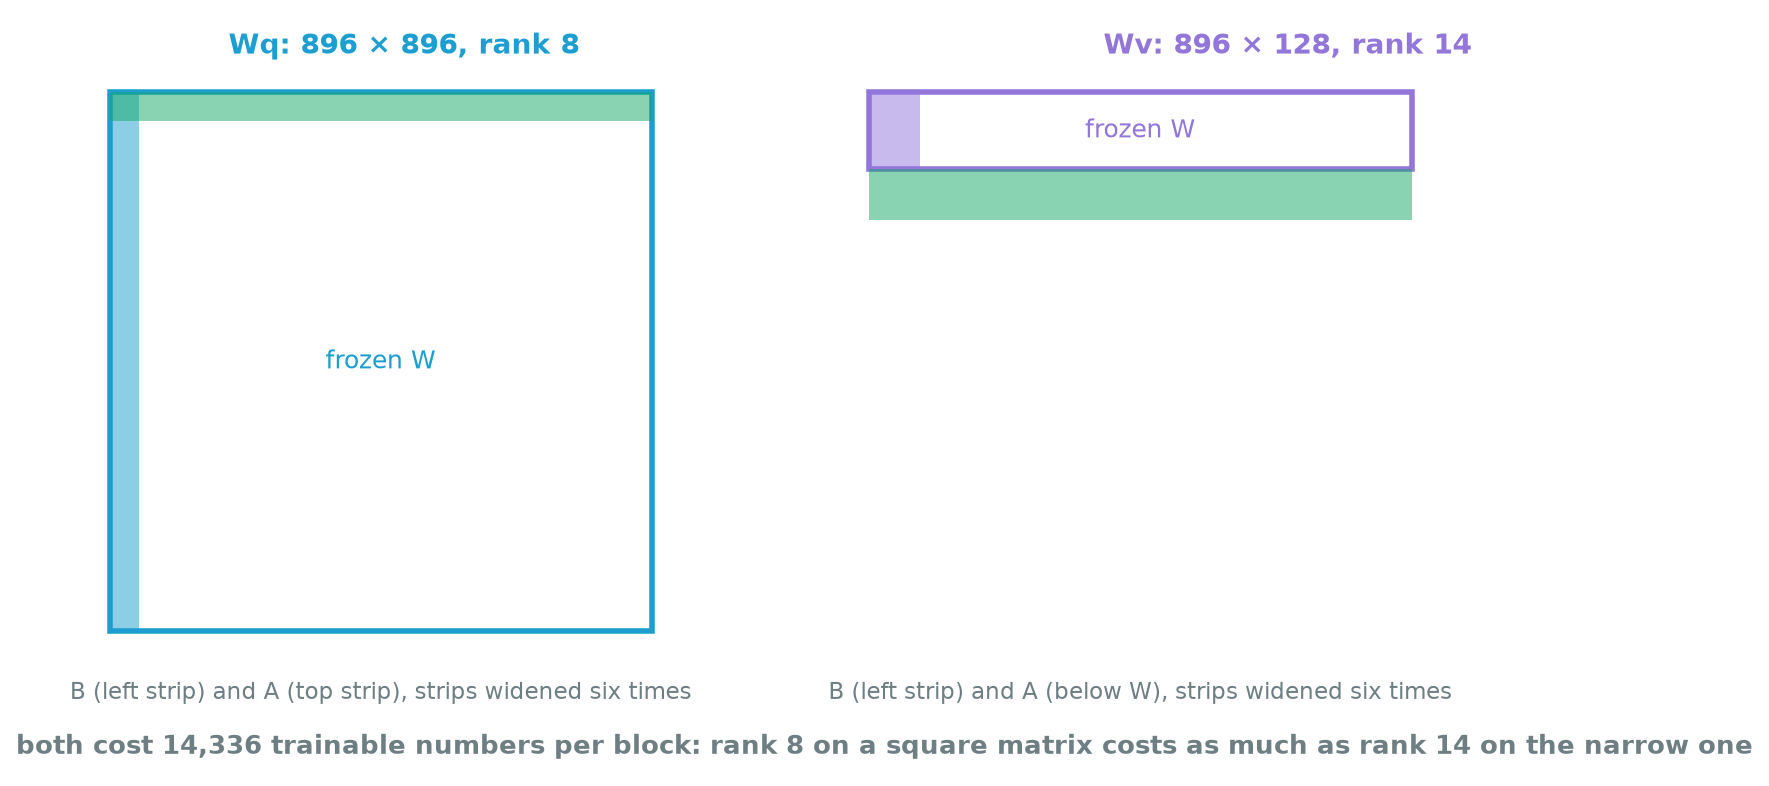

*Figure 12.3 — Equal budgets, different ranks, with the matrices drawn to scale. Because of grouped-query attention, Wq is 896 × 896 but Wv is only 896 × 128, so rank 8 on Wq and rank 14 on Wv both cost 14,336 trainable numbers per block.*

In [4]:
dims = {n: (getattr(inst.model.layers[0].self_attn, n).in_features, getattr(inst.model.layers[0].self_attn, n).out_features) for n in ("q_proj", "k_proj", "v_proj", "o_proj")}
per_rank = {n: i + o for n, (i, o) in dims.items()}; BUDGET = 8 * per_rank["q_proj"]                     # rank 8 on Wq, per block, as in the paper's Table 5
CONFIGS = {"Wq": ["q_proj"], "Wk": ["k_proj"], "Wv": ["v_proj"], "Wo": ["o_proj"], "Wq, Wk": ["q_proj", "k_proj"], "Wq, Wv": ["q_proj", "v_proj"], "Wq, Wk, Wv, Wo": ["q_proj", "k_proj", "v_proj", "o_proj"]}
ranks = {c: max(1, BUDGET // sum(per_rank[n] for n in ns)) for c, ns in CONFIGS.items()}
print("matrix sizes (in, out):", dims, f"; budget per block: {BUDGET:,} trainable numbers")
print("rank per matrix and actual budget:", {c: (ranks[c], ranks[c] * sum(per_rank[n] for n in ns)) for c, ns in CONFIGS.items()})
STEPS, SEEDS = 60, (0, 1, 2); res = []; t0 = time.perf_counter()
for c, ns in CONFIGS.items():
    for seed in SEEDS:
        set_seed(seed); m = add_lora(inst, {n: ranks[c] for n in ns}); finetune(m, lora_parameters(m), STEPS, seed=seed)
        res.append({"weights adapted": c, "rank": ranks[c], "seed": seed, "loss, training layouts": heldout_loss(m, test_seen), "loss, unseen layouts": heldout_loss(m, test_unseen)}); del m; torch.cuda.empty_cache()
res = pd.DataFrame(res); print(f"{len(res)} runs of {STEPS} steps in {time.perf_counter() - t0:.0f} s")
summ = res.groupby("weights adapted", sort=False).agg(rank=("rank", "first"), train_mean=("loss, training layouts", "mean"), train_sd=("loss, training layouts", "std"), unseen_mean=("loss, unseen layouts", "mean"), unseen_sd=("loss, unseen layouts", "std"))
display(summ.round(4))

matrix sizes (in, out): {'q_proj': (896, 896), 'k_proj': (896, 128), 'v_proj': (896, 128), 'o_proj': (896, 896)} ; budget per block: 14,336 trainable numbers
rank per matrix and actual budget: {'Wq': (8, 14336), 'Wk': (14, 14336), 'Wv': (14, 14336), 'Wo': (8, 14336), 'Wq, Wk': (5, 14080), 'Wq, Wv': (5, 14080), 'Wq, Wk, Wv, Wo': (2, 11264)}


21 runs of 60 steps in 646 s


,rank,train_mean,train_sd,unseen_mean,unseen_sd
weights adapted,,,,,
Wq,8,0.0027,0.0003,0.0908,0.0036
Wk,14,0.0161,0.0009,0.1028,0.0028
Wv,14,0.0022,0.0001,0.0963,0.0024
Wo,8,0.0008,0.0000,0.0728,0.0024
"Wq, Wk",5,0.0016,0.0001,0.0969,0.0083
"Wq, Wv",5,0.0011,0.0000,0.0902,0.0069
"Wq, Wk, Wv, Wo",2,0.0006,0.0000,0.0728,0.0050


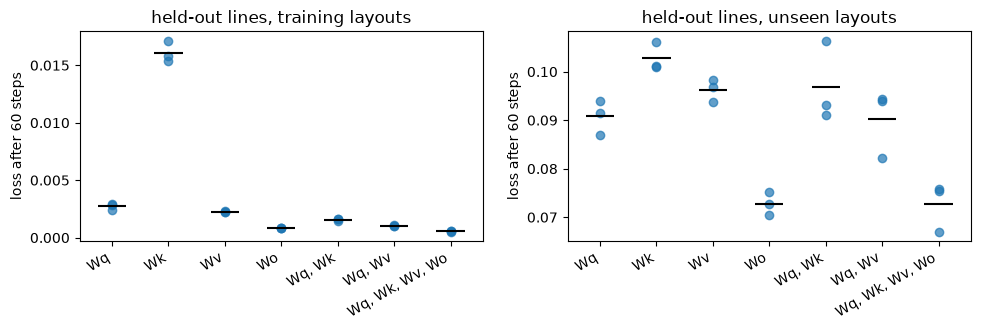

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, col, title in zip(ax, ("loss, training layouts", "loss, unseen layouts"), ("held-out lines, training layouts", "held-out lines, unseen layouts")):
    for i, c in enumerate(CONFIGS): v = res[res["weights adapted"] == c][col]; a_.scatter([i] * len(v), v, color="C0", alpha=0.7); a_.hlines(v.mean(), i - 0.25, i + 0.25, color="k")
    a_.set_xticks(range(len(CONFIGS))); a_.set_xticklabels(CONFIGS, rotation=30, ha="right"); a_.set_ylabel("loss after 60 steps"); a_.set_title(title)
plt.tight_layout(); plt.show()

On the training layouts every configuration is close to zero after 60 steps (0.0006 to 0.0161), so the comparison lives in the right-hand plot, the unseen layouts. There, with 3 seeds each and standard deviations of 0.002 to 0.008:

- $W_o$ alone and all four matrices are best, both at 0.0728.
- $W_k$ alone is worst (0.1028), and $W_q, W_k$ (0.0969) is no better than $W_q$ alone (0.0908).
- $W_v$ alone (0.0963) is no better than $W_q$ alone, and $W_q, W_v$ (0.0902) is no better than $W_q$ alone either.

Three of the paper's findings reproduce: $W_k$ is the weakest choice, $W_o$ alone is among the best, and adapting all four is as good as anything. Two do not: here $W_v$ alone is weak, and $W_q, W_v$ falls well short of all four (0.0902 against 0.0728), where in the paper it matched them. Differences of scale, task and architecture (grouped-query attention changes what $W_v$ is) are all candidate reasons; this experiment cannot say which.

## 3. Do different ranks learn the same directions? (Figure 3)

The paper's explanation for why rank 1 is enough: train adapters with r = 8 and r = 64, and their top direction is the same. It measures this with the subspace similarity

$$\phi(i, j) = \frac{\lVert U_i^\top V_j \rVert_F^2}{\min(i, j)},$$

where $U_i$ and $V_j$ hold the top $i$ and top $j$ singular vectors of the two adapters. It is 1 when one subspace lies inside the other and about $j/d$ for random directions in $d$ dimensions. In layer 48 of GPT-3 the paper reports $\phi > 0.5$ for the top direction of $A_{r=8}$ and $A_{r=64}$.

We train adapters on $W_q$ and $W_v$ for 250 steps: r = 8 with seed 0, r = 64 with seeds 1 and 2, and compare block 13 of 24. We compute $\phi$ on $A$, as the paper does, and also on the output directions of the learned update $BA$; the paper's footnote 7 notes that the same analysis can be done with $B$.

> **Pause:** $A$ starts as a random matrix and $B$ at zero. Which of the two will carry what the adapter learned?

3 adapters (Wq and Wv) of 250 steps in 550 s; held-out loss on the training layouts: r=8 0.0002, r=64 0.0002, r=64 other seed 0.0002
q_proj: training moved A by 15.9% (r=8) and 15.1% (r=64) of its starting size
v_proj: training moved A by 15.9% (r=8) and 16.1% (r=64) of its starting size


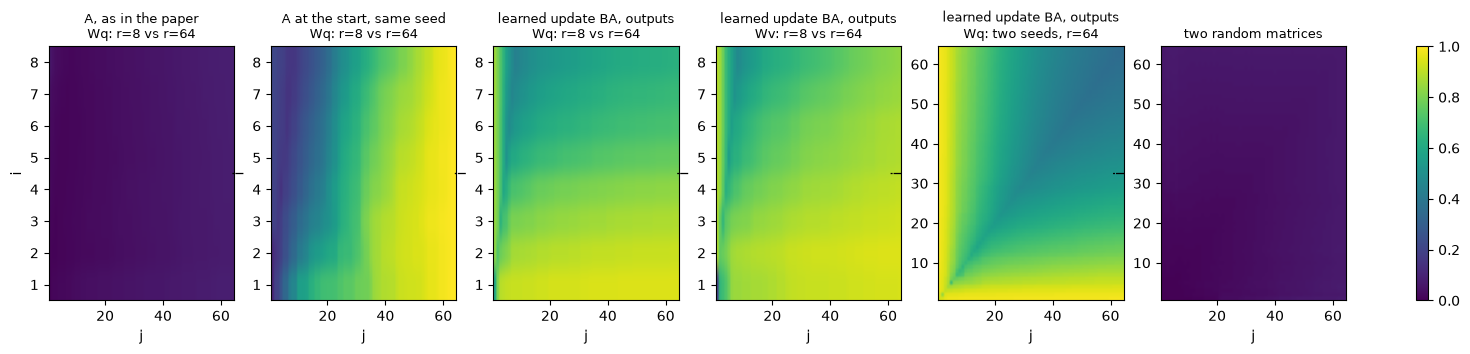

A, as in the paper: Wq: r=8 vs r=64                        φ(1,1) = 0.01; φ(8,8) = 0.02; φ(8,64) = 0.09
A at the start, same seed: Wq: r=8 vs r=64                 φ(1,1) = 0.10; φ(8,8) = 0.16; φ(8,64) = 1.00
learned update BA, outputs: Wq: r=8 vs r=64                φ(1,1) = 0.59; φ(8,8) = 0.43; φ(8,64) = 0.64
learned update BA, outputs: Wv: r=8 vs r=64                φ(1,1) = 0.20; φ(8,8) = 0.47; φ(8,64) = 0.84
learned update BA, outputs: Wq: two seeds, r=64            φ(1,1) = 0.93; φ(8,8) = 0.67; φ(8,64) = 0.87
two random matrices                                        φ(1,1) = 0.00; φ(8,8) = 0.01; φ(8,64) = 0.07
expected for random directions: φ(1,1) about 1/d, φ(8,64) about 64/d, with d = 896 for Wq (0.07) and d = 128 for Wv's outputs (0.50)


In [6]:
def lora_A(m): return {n: getattr(m.model.layers[LAYER].self_attn, n).A.detach().float().cpu().clone() for n in ("q_proj", "v_proj")}
def train_adapter(r, seed, steps=250):
    set_seed(seed); m = add_lora(inst, {"q_proj": r, "v_proj": r}); A0 = lora_A(m); finetune(m, lora_parameters(m), steps, seed=seed)
    out = {n: (getattr(m.model.layers[LAYER].self_attn, n).A.detach().float().cpu(), getattr(m.model.layers[LAYER].self_attn, n).B.detach().float().cpu()) for n in ("q_proj", "v_proj")}
    loss = heldout_loss(m, test_seen); del m; torch.cuda.empty_cache(); return out, A0, loss
LAYER = 12                                                                               # a middle block of 24, as the paper used layer 48 of 96
t0 = time.perf_counter(); (ad8, A0_8, l8), (ad64, A0_64, l64), (ad64b, _, l64b) = train_adapter(8, 0), train_adapter(64, 1), train_adapter(64, 2)
print(f"3 adapters (Wq and Wv) of 250 steps in {time.perf_counter() - t0:.0f} s; held-out loss on the training layouts: r=8 {l8:.4f}, r=64 {l64:.4f}, r=64 other seed {l64b:.4f}")
for n in ("q_proj", "v_proj"): print(f"{n}: training moved A by {(ad8[n][0] - A0_8[n]).norm() / A0_8[n].norm():.1%} (r=8) and {(ad64[n][0] - A0_64[n]).norm() / A0_64[n].norm():.1%} (r=64) of its starting size")
def phi_U(U1, U2, i_max, j_max): return np.array([[(U1[:, :i].T @ U2[:, :j]).pow(2).sum().item() / min(i, j) for j in range(1, j_max + 1)] for i in range(1, i_max + 1)])
def right_vectors(A): return torch.linalg.svd(A, full_matrices=False).Vh.T                # columns: right-singular vectors of A, in order of singular value
def update_out(ad, n): A, B = ad[n]; return torch.linalg.svd(B @ A, full_matrices=False).U  # output directions of the learned update dW = BA
g = torch.Generator().manual_seed(0); R1, R2 = torch.randn(64, 896, generator=g), torch.randn(64, 896, generator=g)
set_seed(0); m = add_lora(inst, {"q_proj": 64, "v_proj": 64}); A0_64same = lora_A(m); del m; torch.cuda.empty_cache()   # rank 64 with the SAME seed as rank 8, untrained
maps = {"A, as in the paper\nWq: r=8 vs r=64": phi_U(right_vectors(ad8["q_proj"][0]), right_vectors(ad64["q_proj"][0]), 8, 64),
        "A at the start, same seed\nWq: r=8 vs r=64": phi_U(right_vectors(A0_8["q_proj"]), right_vectors(A0_64same["q_proj"]), 8, 64),
        "learned update BA, outputs\nWq: r=8 vs r=64": phi_U(update_out(ad8, "q_proj"), update_out(ad64, "q_proj"), 8, 64),
        "learned update BA, outputs\nWv: r=8 vs r=64": phi_U(update_out(ad8, "v_proj"), update_out(ad64, "v_proj"), 8, 64),
        "learned update BA, outputs\nWq: two seeds, r=64": phi_U(update_out(ad64, "q_proj"), update_out(ad64b, "q_proj"), 64, 64),
        "two random matrices": phi_U(right_vectors(R1), right_vectors(R2), 64, 64)}
fig, axes = plt.subplots(1, 6, figsize=(18, 3.3))
for a_, (k, v) in zip(axes, maps.items()): im = a_.imshow(v, aspect="auto", origin="lower", vmin=0, vmax=1, cmap="viridis", extent=(0.5, v.shape[1] + 0.5, 0.5, v.shape[0] + 0.5)); a_.set_title(k, fontsize=9); a_.set_xlabel("j"); a_.set_ylabel("i")
fig.colorbar(im, ax=axes, fraction=0.02); plt.show()
for k, v in maps.items(): print(f"{k.replace(chr(10), ': '):58s} φ(1,1) = {v[0, 0]:.2f}; φ(8,8) = {v[7, 7]:.2f}; φ(8,64) = {v[7, -1]:.2f}")
print(f"expected for random directions: φ(1,1) about 1/d, φ(8,64) about 64/d, with d = 896 for Wq ({64 / 896:.2f}) and d = 128 for Wv's outputs ({64 / 128:.2f})")

Computed on $A$ as in the paper, the r = 8 and r = 64 adapters look unrelated: $\phi(1,1) = 0.01$ and $\phi(8,64) = 0.09$, where random directions give about 0.07. The reason is in the second line of output: training moved $A$ by only about 16% of its starting size. $A$ is still mostly its random start, and the two adapters started from different random numbers.

The second panel shows how easily this goes wrong. Two untrained adapters made with the **same** seed give $\phi(8,64) = 1.00$: the random generator produced the same numbers for the start of both matrices. Our first run of this notebook used the same seed for r = 8 and r = 64 and showed exactly this pattern, which looks like strong agreement and is pure initialisation.

On the learned update the paper's claim holds for $W_q$: the top output direction of the r = 8 and r = 64 updates overlap with $\phi(1,1) = 0.59$, where random directions in 896 dimensions give about 0.001, and two r = 64 runs with different seeds share it with $\phi(1,1) = 0.93$. For $W_v$, whose output has only 128 dimensions, the top direction overlaps at 0.20, far above the random 0.008 but below the paper's 0.5.

## 4. How does the update relate to W? (Table 7)

Table 7 asks whether $\Delta W$ repeats what $W$ already does. It projects $W_q$ onto the top-$r$ directions of $\Delta W_q$ ($\lVert U^\top W_q V^\top \rVert_F$) and compares with $W_q$'s own top directions and with random directions. In layer 48 of GPT-3 with r = 4 it reports 0.32 along $\Delta W$'s directions, 21.67 along $W$'s own, and 0.02 along random ones, with $\lVert W_q \rVert_F = 61.95$ and $\lVert \Delta W_q \rVert_F = 6.91$. The paper reads this as: $\Delta W$ amplifies directions that $W$ already has but does not emphasise, by a factor of about $6.91 / 0.32 \approx 21.5$. We repeat it with the r = 8 adapter from section 3.

In [7]:
W = inst.model.layers[LAYER].self_attn.q_proj.weight.detach().float().cpu(); A, B = ad8["q_proj"]; dW = (16 / 8) * (B @ A)
def proj_norm(U, V): return (U.T @ W @ V).norm().item()                                  # ||U^T W V||_F for U (out x r) and V (in x r)
Ud, Sd, Vdh = torch.linalg.svd(dW, full_matrices=False); Uw, Sw, Vwh = torch.linalg.svd(W, full_matrices=False); r = 8
Qu, _ = torch.linalg.qr(torch.randn(W.shape[0], r, generator=g)); Qv, _ = torch.linalg.qr(torch.randn(W.shape[1], r, generator=g))
t7 = {"directions of ΔW": proj_norm(Ud[:, :r], Vdh[:r].T), "top directions of W": proj_norm(Uw[:, :r], Vwh[:r].T), "random directions": proj_norm(Qu, Qv)}
print(f"block {LAYER + 1}, query matrix: ||W||_F = {W.norm():.2f}, ||ΔW||_F = {dW.norm():.3f} (rank 8, scaled by alpha/r)")
for k, v in t7.items(): print(f"  ||U^T W V||_F along the {k}: {v:.3f}")
print(f"amplification ||ΔW||_F / ||U^T W V||_F along ΔW's own directions: {dW.norm() / t7['directions of ΔW']:.1f}")

block 13, query matrix: ||W||_F = 19.28, ||ΔW||_F = 0.275 (rank 8, scaled by alpha/r)
  ||U^T W V||_F along the directions of ΔW: 0.158
  ||U^T W V||_F along the top directions of W: 6.131
  ||U^T W V||_F along the random directions: 0.164
amplification ||ΔW||_F / ||U^T W V||_F along ΔW's own directions: 1.7


The first part reproduces: $W$ is 6.131 along its own top directions and only 0.158 along $\Delta W$'s, so the update does not repeat $W$'s strongest directions. The rest does not. Along $\Delta W$'s directions $W$ is no larger than along random ones (0.164), where in GPT-3 it was 16 times larger, and the amplification factor is 1.7 instead of about 21.5. Our update is also small: $\lVert \Delta W \rVert_F = 0.275$ against $\lVert W \rVert_F = 19.28$.

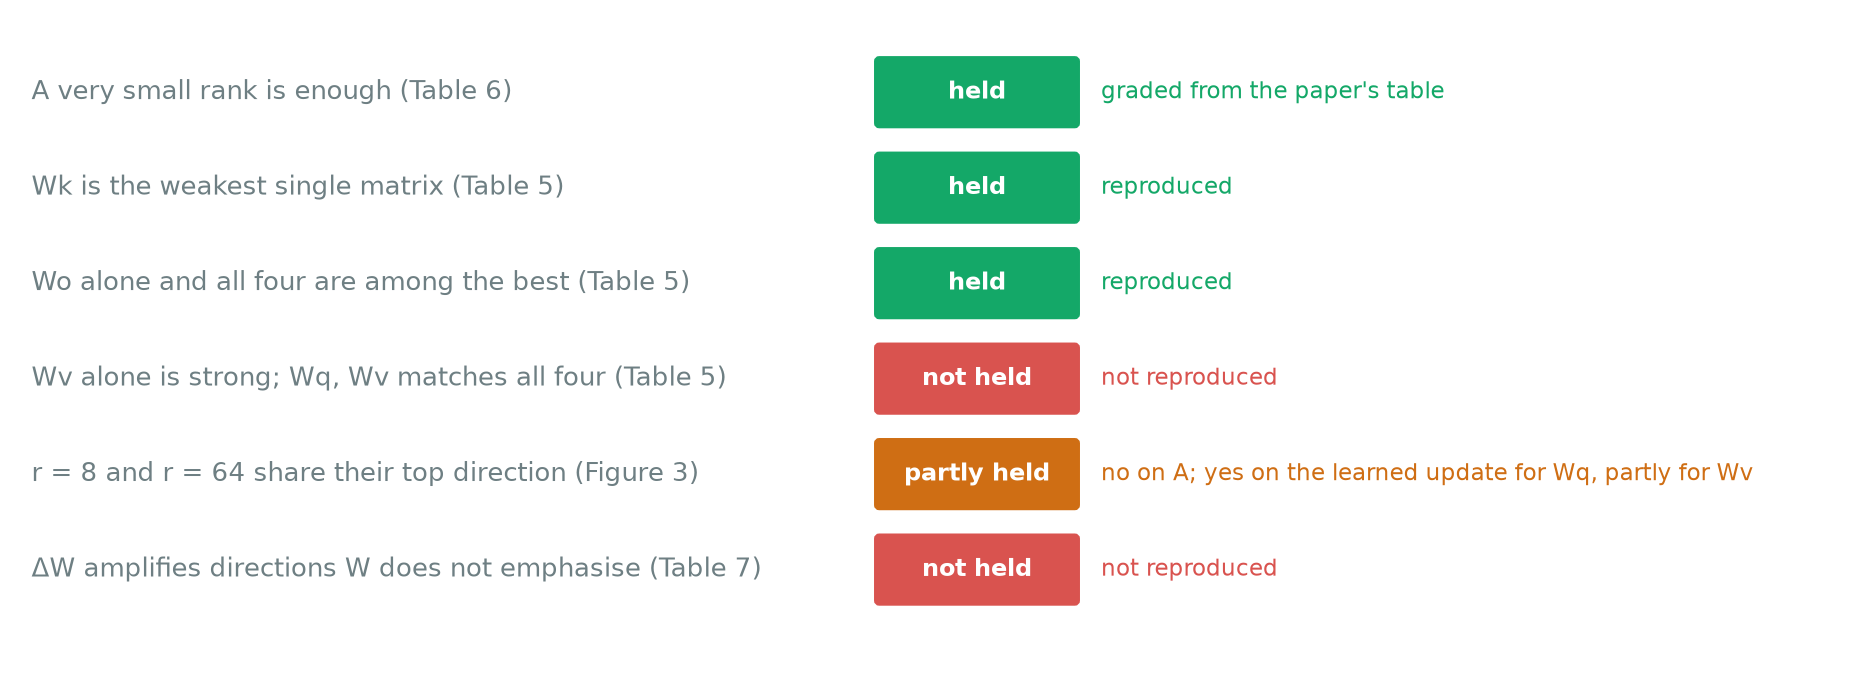

*Figure 12.4 — The claims scoreboard. For each claim from the paper that was graded or tested, whether it held here, held in part, or did not hold.*

## What to take away

| Claim | Paper (GPT-3 175B) | Here (Qwen2.5-0.5B, one task) |
|---|---|---|
| A very small rank is enough (Table 6) | supported by its own error bars; "r = 8 is best" is not | not tested directly (graded from the table) |
| $W_k$ is the weakest single matrix (Table 5) | 70.0 | reproduced |
| $W_o$ alone and all four are among the best (Table 5) | 73.2, 73.7 | reproduced |
| $W_v$ alone is strong; $W_q, W_v$ matches all four (Table 5) | 73.0; 73.7 vs 73.7 | not reproduced |
| r = 8 and r = 64 share their top direction (Figure 3) | $\phi > 0.5$ on $A$ | on $A$: no, $A$ barely trains; on the learned update: yes for $W_q$ (0.59), partly for $W_v$ |
| $\Delta W$ amplifies directions $W$ does not emphasise (Table 7) | factor ≈ 21.5 | does not repeat $W$'s top directions; no amplification beyond random (1.7) |

- Map a paper before reading it closely: question, method, evidence, scale. Most claims are supported by one table at one scale.
- Grade claims with the paper's own noise. A difference the size of one seed's standard deviation supports nothing.
- A small reproduction tests whether a finding transfers, not whether the paper is right. Report which parts held, which did not, and at what scale.
- Check what an analysis measures before trusting a striking picture: a matrix that barely moves from its random start, or two runs that share random numbers, can produce a convincing heatmap.

---

# Going deeper

Reading for after the session.

## Paper and code disagree on the initialisation

§4.1 says $A$ uses "random Gaussian initialization". The official code (`loralib/layers.py`, `Linear.reset_parameters`) uses `nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))`, a uniform distribution, which is also what Sessions 7 and 12 use. For a `LoRA` embedding layer the same file does the opposite: $A$ at zero and $B$ normal. Differences like these are common; when a result depends on details, the code is the more reliable description of what was run.

## What the paper claims about cost

§4.2: on GPT-3 175B, training memory falls from 1.2 TB to 350 GB, and with r = 4 on $W_q$ and $W_v$ the checkpoint falls from 350 GB to 35 MB, about 10,000 times smaller; training is about 25% faster because most gradients are not computed. Session 7 measured the same effect at our scale: an adapter file is a tiny fraction of the model.

## Why A barely moves

$B$ starts at zero, so at the start the gradient with respect to $A$ is zero too (it is multiplied by $B$); $A$ only begins to change once $B$ has grown. With a learning rate tuned for $B$ and a task learned in a few hundred steps, $A$ stays close to its random start, as section 3 measured (about 16%). The paper's adapters were trained much longer on harder tasks. Several later methods change this balance on purpose, for example by using a larger learning rate for $B$ than for $A$, or by initialising $A$ and $B$ from the singular vectors of $W$.

## Reasons the Table 7 numbers differ

Our task is easy and was learned within 250 steps, so the update is small (1.4% of $\lVert W \rVert_F$, against 11% in the paper's layer 48), and we used r = 8 against the paper's r = 4. Either could change the amplification factor; this session did not test which. A fair next experiment trains on a harder task, at r = 4, and measures Table 7 at several points during training.

## A note on the paper's prose

The text of §7.2 lists the adapted set as "{Wq, Wk, Wv, Wc}", a typo for $W_o$ (Table 5 itself uses $W_o$). Small inconsistencies like this are worth noting when you reproduce a paper, so that you are sure you ran what the authors ran.

## Changes from the earlier version of this session

The earlier course discussed reading papers in general and included a results table that was not from any paper and a timeline that put GPT-3 before Kaplan et al.'s scaling-law paper. This version works with one real paper, quotes only numbers checked against its text, and reproduces three of its claims.